# Navier–Stokes, Re = 500, 1024 × 1024 (application)

**Source:** neuraloperator Zenodo record 12825163 (`nsforcing_1024_{train,test}.pt`, CC BY 4.0), the benchmark of
Kossaifi et al. 2023 (MG-TFNO, arXiv:2310.00120). 2D incompressible Navier–Stokes on the torus at Reynolds number 500
with zero initial vorticity; **the input is the forcing f** (a Gaussian random field, covariance 27(−Δ+9I)⁻⁴) and the
output the vorticity at T = 5. The map is exactly translation-equivariant. 1000 train + 1000 test fields at 1024²;
a separate 128² release has 10000 train + 2000 test. Published test rL2 (trained at 128², 10k samples):
FNO 1.34%, TFNO 0.22–0.47%, TFNO tested zero-shot at 1024² 0.3%.

Loader: `sgpo.data.benchmarks.ns1024` (`ns1024@sub=k` keeps every k-th point). Split used here: train 900, val 100
from the train file, test 200 from the official test file. The sections below look at how hard the map is,
independently of any model.

In [1]:
import sys; sys.path.insert(0, "..")
import math, numpy as np, torch, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
rel = lambda p, t: ((p - t).flatten(1).norm(dim=1) / t.flatten(1).norm(dim=1))
from sgpo.data.benchmarks import RAW
RAW = f"{RAW}/zenodo/ns1024"
tr = torch.load(f"{RAW}/nsforcing_1024_train.pt", mmap=True, weights_only=True)
te = torch.load(f"{RAW}/nsforcing_1024_test.pt", mmap=True, weights_only=True)
NTR, NTE = 300, 100                                  # subsets keep the notebook light (full fields, 1024^2)
x, y = tr["x"][:NTR].clone(), tr["y"][:NTR].clone()
xt, yt = te["x"][:NTE].clone(), te["y"][:NTE].clone()
pd.DataFrame({k: {"shape": tuple(v.shape), "mean": float(v.mean()), "std": float(v.std()), "min": float(v.min()), "max": float(v.max())}
              for k, v in {"x (train)": x, "y (train)": y, "x (test)": xt, "y (test)": yt}.items()}).T

,shape,mean,std,min,max
x (train),"(300, 1024, 1024)",-0.0,0.224626,-0.942367,1.172765
y (train),"(300, 1024, 1024)",-0.0,0.922872,-4.013199,4.230763
x (test),"(100, 1024, 1024)",0.0,0.227365,-0.97427,0.978863
y (test),"(100, 1024, 1024)",0.0,0.930521,-3.929573,4.333786


## What the fields look like
Full field and a 128 × 128 zoom: the fine-scale filaments are what a 1024² model must get right.

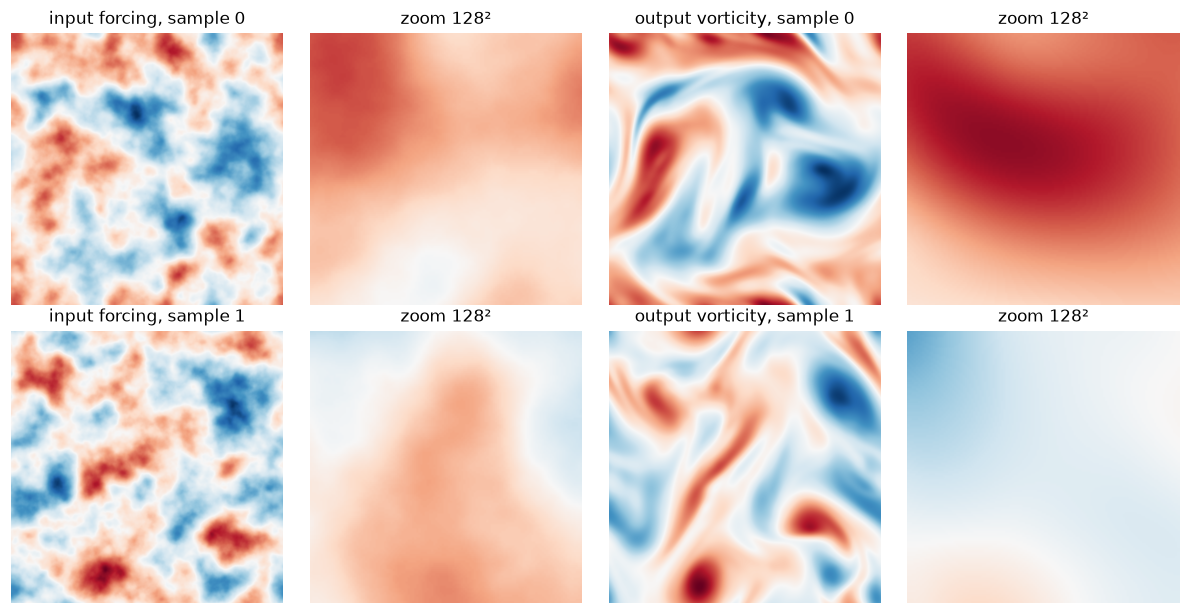

In [2]:
fig, ax = plt.subplots(2, 4, figsize=(11, 5.6))
for j in range(2):
    for c, (v, t) in enumerate([(x[j], "input forcing"), (y[j], "output vorticity")]):
        l = v.abs().max()
        ax[j, 2 * c].imshow(v, cmap="RdBu_r", vmin=-l, vmax=l); ax[j, 2 * c].set_title(f"{t}, sample {j}")
        ax[j, 2 * c + 1].imshow(v[:128, :128], cmap="RdBu_r", vmin=-l, vmax=l); ax[j, 2 * c + 1].set_title("zoom 128²")
for a in ax.flat: a.axis("off")
plt.tight_layout()

## Energy spectra
Turbulence puts energy at many scales. The share of output energy at high wavenumbers bounds what any smooth, low-mode model can capture.

output energy above k=8      1.633472e-02
output energy above k=16     1.038784e-03
output energy above k=32     1.014464e-05
output energy above k=64     1.210536e-08
output energy above k=128    1.500408e-10
output energy above k=256    1.676548e-12
dtype: float64

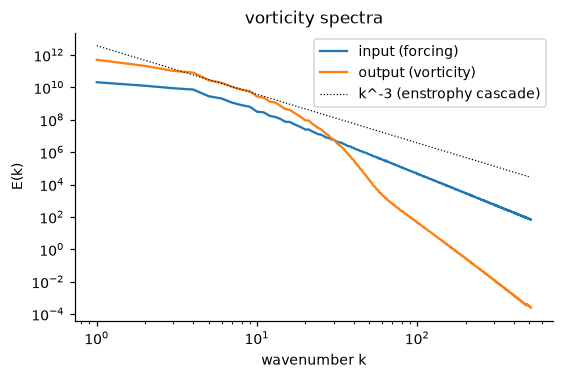

In [3]:
def spectrum(t):
    F = torch.fft.fft2(t.double()).abs().pow(2).mean(0); n = t.shape[-1]
    k = torch.fft.fftfreq(n, 1 / n); r = (k[None] ** 2 + k[:, None] ** 2).sqrt().round().long()
    return torch.zeros(r.max() + 1, dtype=torch.float64).scatter_add_(0, r.flatten(), F.flatten())[: n // 2]
Ex, Ey = spectrum(x[:50]), spectrum(y[:50])
kk = torch.arange(1, len(Ex))
plt.figure(figsize=(5.6, 3.4)); plt.loglog(kk, Ex[1:], label="input (forcing)"); plt.loglog(kk, Ey[1:], label="output (vorticity)")
plt.loglog(kk, Ey[8] * (kk / 8.0) ** -3, "k:", lw=0.8, label="k^-3 (enstrophy cascade)")
plt.xlabel("wavenumber k"); plt.ylabel("E(k)"); plt.legend(); plt.title("vorticity spectra")
cum = Ey.cumsum(0) / Ey.sum()
pd.Series({f"output energy above k={k}": float(1 - cum[k]) for k in (8, 16, 32, 64, 128, 256)})

## How much of the output is the input?
With zero initial vorticity, the response to a forcing is linear at early times and becomes nonlinear by T = 5; `y ≈ a·x` and a per-mode linear map measure how much is linear.

In [4]:
a_ = ((x * y).sum() / (x * x).sum()).item()
corr = torch.stack([torch.corrcoef(torch.stack([x[i].flatten(), y[i].flatten()]))[0, 1] for i in range(50)])
def lowpass(t, kmax):
    F = torch.fft.rfft2(t); n = t.shape[-1]; ky = torch.fft.fftfreq(n, 1 / n).abs()[:, None]; kx = torch.arange(F.shape[-1])[None]
    return torch.fft.irfft2(F * ((ky <= kmax) & (kx <= kmax)), s=t.shape[-2:])
rows = {"predict zero (= 100%)": rel(0 * yt, yt).mean(), "persistence y = a x": rel(a_ * xt, yt).mean(),
        "train-mean field": rel(y.mean(0).expand_as(yt), yt).mean()}
for k in (16, 32, 64):
    rows[f"truth low-passed to k<={k} (resolution floor)"] = rel(lowpass(yt, k), yt).mean()
print(f"pointwise corr(x, y) per sample: median {corr.median():.3f}; persistence gain a = {a_:.3f}")
pd.Series({k: f"{100 * float(v):.1f}%" for k, v in rows.items()}, name="test rL2")

pointwise corr(x, y) per sample: median 0.631; persistence gain a = 2.613


predict zero (= 100%)                           100.0%
persistence y = a x                              77.9%
train-mean field                                100.2%
truth low-passed to k<=16 (resolution floor)      2.4%
truth low-passed to k<=32 (resolution floor)      0.2%
truth low-passed to k<=64 (resolution floor)      0.0%
Name: test rL2, dtype: str

## Is the map learnable from the data we have? Nearest-neighbour test
For each test input, the training input closest to it (at 64², after removing the mean): if close inputs give very different outputs, the map is chaotic at this horizon and errors stay high whatever the model.

nearest training input: median relative input distance 1.103; output rL2 of copying its output 109.8%


Text(0.5, 1.0, 'sensitivity of the map')

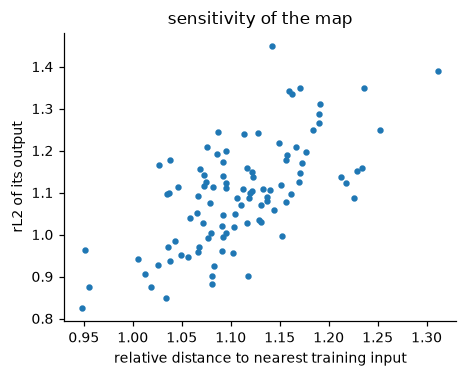

In [5]:
s = 16                                                    # compare at 64^2
f = lambda t: t[:, ::s, ::s].flatten(1)
D = torch.cdist(f(xt), f(x)); j = D.argmin(1)
dx = (D.min(1).values / f(xt).norm(dim=1))
dy = rel(y[j], yt)
print(f"nearest training input: median relative input distance {dx.median():.3f}; output rL2 of copying its output {100 * dy.median():.1f}%")
plt.figure(figsize=(4.6, 3.4)); plt.scatter(dx, dy, s=10); plt.xlabel("relative distance to nearest training input"); plt.ylabel("rL2 of its output")
plt.title("sensitivity of the map")

## A linear operator baseline
A per-Fourier-mode linear map (the operator a single linear spectral layer can represent), fitted by least squares at 128² on the training subset. Its error is a floor for what *linear* structure explains.

In [6]:
s = 8; n = 1024 // s
X, Y = torch.fft.rfft2(x[:, ::s, ::s].double()), torch.fft.rfft2(y[:, ::s, ::s].double())
G = (X.conj() * Y).sum(0) / ((X.abs() ** 2).sum(0) + 1e-12)       # per-mode least squares
Xt = torch.fft.rfft2(xt[:, ::s, ::s].double())
pred = torch.fft.irfft2(G * Xt, s=(n, n))
print(f"diagonal Fourier linear map at {n}²: test rL2 {100 * rel(pred, yt[:, ::s, ::s].double()).mean():.1f}%")

diagonal Fourier linear map at 128²: test rL2 66.3%


## Train vs test distribution

train x std    0.224626
test x std     0.227365
train y std    0.922872
test y std     0.930521
dtype: float64

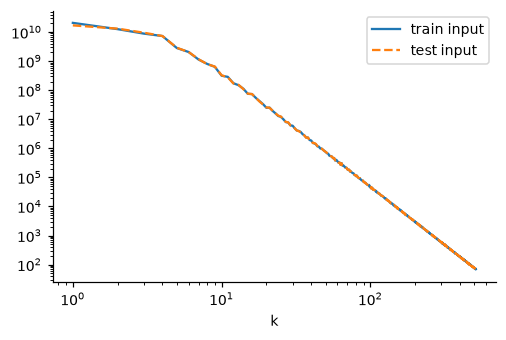

In [7]:
Et = spectrum(xt[:50]); plt.figure(figsize=(5.2, 3.2))
plt.loglog(kk, Ex[1:], label="train input"); plt.loglog(kk, Et[1:], "--", label="test input"); plt.legend(); plt.xlabel("k")
pd.Series({"train x std": float(x.std()), "test x std": float(xt.std()), "train y std": float(y.std()), "test y std": float(yt.std())})

## Takeaways for training
Read the numbers above together:
* **Resolution floor:** the low-pass rows give the error of the *truth itself* truncated at k; a model that only resolves
  low modes cannot beat them.
* **Nearest neighbour:** independent forcings are far apart (relative distance ~1), so copying a neighbour's output
  fails; this says the input space is not densely sampled, not that the map is chaotic (FNO reaches 1.34%).
* **Symmetry:** the map is translation-equivariant; a model with location-specific weights (the WNO's coarse wavelet
  kernel) should be trained with random shifts (`--aug shift2d`), otherwise it can fit positions instead of the map.
* **Linear baseline:** a stage-1 operator should beat the diagonal Fourier map clearly; if it does not, training (not the
  data) is the problem.